# Bump Hunter — LHC $H \to \gamma\gamma$ Resonance Discovery & Statistical Inference

This notebook demonstrates the complete statistical discovery pipeline used in High Energy Physics (ATLAS/CMS at CERN) to detect a resonant signal bump on top of a falling continuum background:

1. **Monte Carlo Event Generation (`data.py`):** Truncated exponential continuum background ($p_b(m) \propto e^{-\lambda m}$) and Gaussian signal ($m_H = 125\text{ GeV}, \sigma = 1.5\text{ GeV}$).
2. **Binned Poisson Likelihood (`likelihood.py`):** Analytical bin expectations $\nu_i(\mu, B_{\text{tot}}, \lambda) = \mu S_{\text{nom}} p_{s,i} + B_{\text{tot}} p_{b,i}$ and Poisson Negative Log-Likelihood (NLL).
3. **Profile Likelihood Ratio & $5\sigma$ Discovery (`discovery.py`):** Asymptotic Wilks' theorem test statistic $q_0 = 2(\text{NLL}_0 - \text{NLL}_1)$ and discovery significance $Z = \sqrt{q_0}$.
4. **Look-Elsewhere Effect & 95% CL Upper Limits (`limits.py`):** Global $p$-value across multiple mass hypotheses ($p_{\text{global}} = 1 - (1 - p_{\text{local}})^{N_{\text{trials}}}$) and one-sided 95% confidence level upper limits ($\mu_{95}$).

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path('../src').resolve()))
from bumphunter import (
    sample_background,
    sample_signal,
    make_binned_data,
    expected_yields,
    poisson_nll,
    fit_background_only,
    fit_signal_plus_background,
    discovery_significance,
    mass_scan,
    upper_limit_95,
)

rng = np.random.default_rng(42)
m_range = (100.0, 160.0)
s_nom = 350.0

bg = sample_background(n_b=20_000, lam=0.03, m_range=m_range, rng=rng)
sig = sample_signal(n_s=350, m_h=125.0, sigma=1.5, m_range=m_range, rng=rng)
counts, edges, centers = make_binned_data(np.concatenate([bg, sig]), m_range=m_range, n_bins=60)

print(f'Generated {len(bg)} background events (mean = {bg.mean():.2f} GeV) and {len(sig)} Higgs signal events (mean = {sig.mean():.2f} GeV)')
print(f'Total binned events across {len(counts)} bins [100, 160] GeV: {counts.sum()}')

Generated 20000 background events (mean = 121.45 GeV) and 350 Higgs signal events (mean = 125.20 GeV)
Total binned events across 60 bins [100, 160] GeV: 20350


## 1. Binned Profile Likelihood Fit & Diphoton Mass Spectrum

We compare two competing hypotheses:
- **Null Hypothesis ($H_0$, Background-Only):** Signal strength fixed to $\mu = 0$, profiling nuisance parameters $(B_{\text{tot}}, \lambda)$.
- **Alternative Hypothesis ($H_1$, Signal + Background):** Free signal strength $\hat{\mu}$ fitted jointly with $(B_{\text{tot}}, \lambda)$.

Best-fit signal strength (mu_hat): 1.081
Test statistic q0 = 2*(NLL_0 - NLL_1): 70.60
Local discovery significance Z: 8.40 sigma (p_local = 2.19e-17)


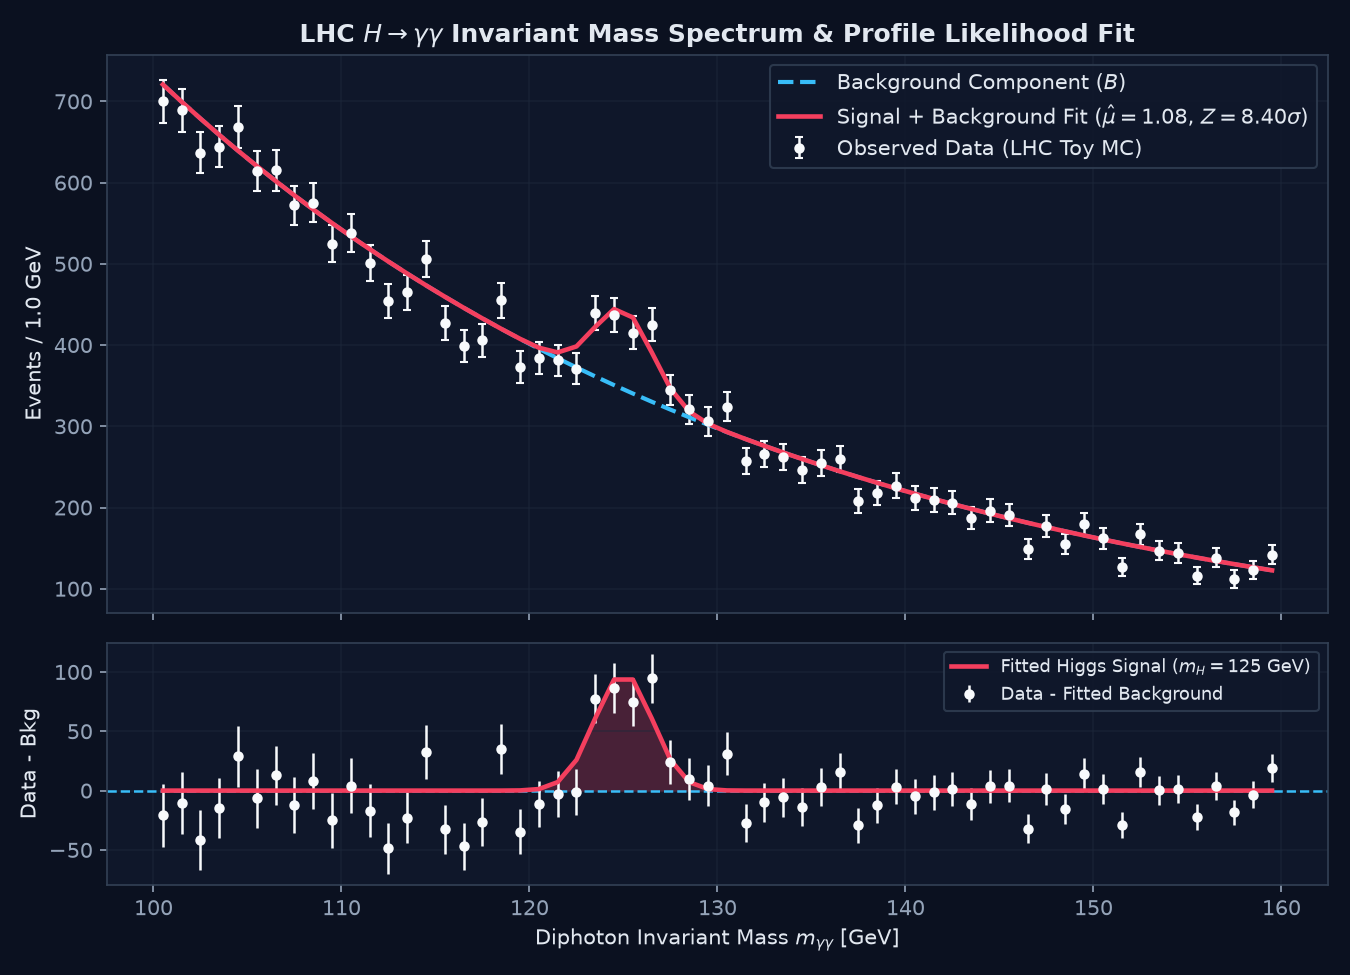

In [2]:
fit0 = fit_background_only(counts, edges, s_nom=s_nom, m_h=125.0, sigma=1.5)
fit1 = fit_signal_plus_background(counts, edges, s_nom=s_nom, m_h=125.0, sigma=1.5)
disc = discovery_significance(counts, edges, s_nom=s_nom, m_h=125.0, sigma=1.5)

print(f"Best-fit signal strength (mu_hat): {disc['mu_hat']:.3f}")
print(f"Test statistic q0 = 2*(NLL_0 - NLL_1): {disc['q0']:.2f}")
print(f"Local discovery significance Z: {disc['z_sig']:.2f} sigma (p_local = {disc['p_value']:.2e})")

nu_b_fit1 = expected_yields(edges, mu=0.0, s_nom=s_nom, b_tot=fit1['b_hat'], lam=fit1['lam_hat'], m_h=125.0, sigma=1.5)
nu_sb_fit1 = expected_yields(edges, mu=fit1['mu_hat'], s_nom=s_nom, b_tot=fit1['b_hat'], lam=fit1['lam_hat'], m_h=125.0, sigma=1.5)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True, gridspec_kw={'height_ratios': [3, 1.3]})
ax1.errorbar(centers, counts, yerr=np.sqrt(counts), fmt='o', markersize=4, label='Observed Data (LHC Toy MC)')
ax1.plot(centers, nu_b_fit1, '--', linewidth=2, label='Background Component (B)')
ax1.plot(centers, nu_sb_fit1, '-', linewidth=2.2, label=f"Signal + Background Fit (mu_hat = {fit1['mu_hat']:.2f}, Z = {disc['z_sig']:.2f} sigma)")
ax1.set_ylabel('Events / 1.0 GeV')
ax1.legend()
ax2.axhline(0.0, linestyle='--')
ax2.errorbar(centers, counts - nu_b_fit1, yerr=np.sqrt(counts), fmt='o', markersize=4)
ax2.plot(centers, nu_sb_fit1 - nu_b_fit1, '-', linewidth=2.2)
ax2.set_xlabel('Diphoton Invariant Mass m_gg [GeV]')
ax2.set_ylabel('Data - Bkg')
plt.tight_layout()
plt.show()

## 2. Profile Likelihood Curve $2\Delta\text{NLL}(\mu)$

Scanning across $\mu$ reveals the parabolic log-likelihood ratio profile around $\hat{\mu}$. Its intercept at $\mu = 0$ defines the discovery test statistic $q_0 = Z^2$.

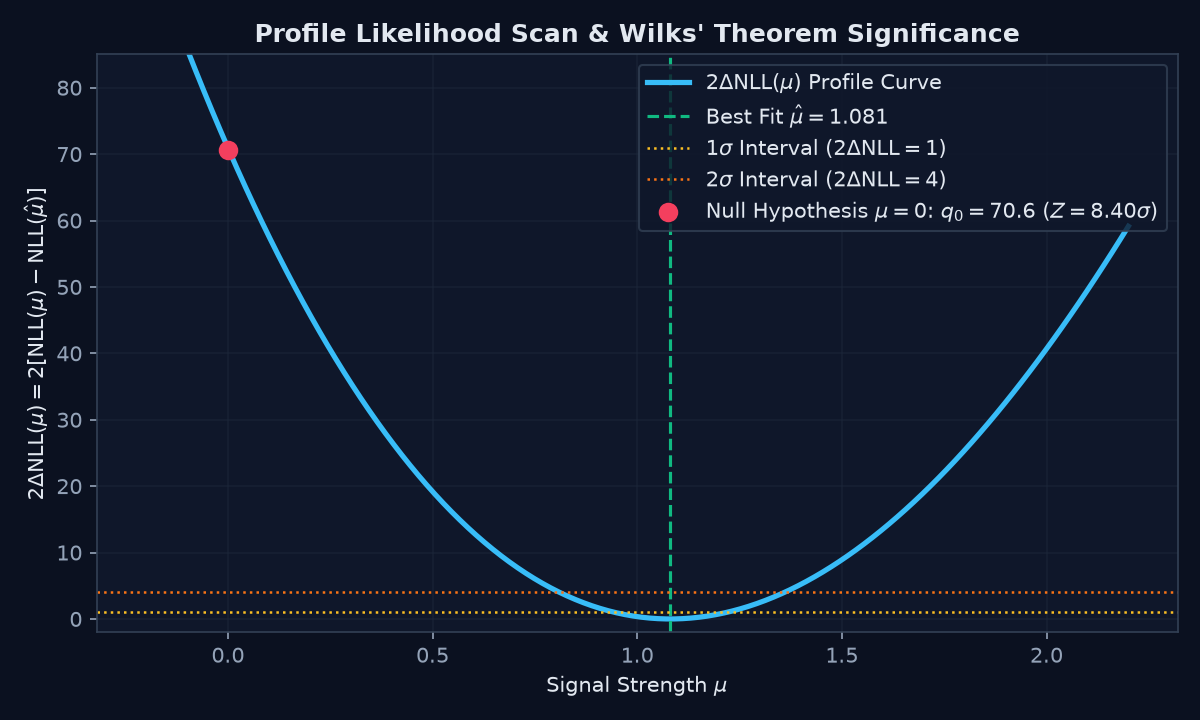

In [3]:
mu_grid = np.linspace(-0.2, 2.2, 120)
dnll_vals = np.array([
    2.0 * (poisson_nll(counts, expected_yields(edges, mu=m, s_nom=s_nom, b_tot=fit1['b_hat'], lam=fit1['lam_hat'])) - fit1['nll'])
    for m in mu_grid
])

plt.figure(figsize=(8, 4.8))
plt.plot(mu_grid, dnll_vals, linewidth=2.5, label='2 Delta NLL(mu)')
plt.axvline(fit1['mu_hat'], linestyle='--', label=f"Best Fit mu_hat = {fit1['mu_hat']:.3f}")
plt.axhline(1.0, linestyle=':', label='1 sigma (2 Delta NLL = 1)')
plt.axhline(4.0, linestyle=':', label='2 sigma (2 Delta NLL = 4)')
plt.xlabel('Signal Strength mu')
plt.ylabel('2 Delta NLL(mu)')
plt.legend()
plt.tight_layout()
plt.show()

## 3. Mass Scan ($110\text{--}150\text{ GeV}$) & Look-Elsewhere Effect & 95% CL Upper Limits

When scanning $N_{\text{trials}} = 41$ mass hypotheses, the probability of observing a background fluctuation anywhere in the search window increases:
$$p_{\text{global}} = 1 - (1 - p_{\text{local}})^{N_{\text{trials}}}$$

Best mass hypothesis: 125.0 GeV
Max Local Significance:  8.40 sigma (p_local = 2.19e-17)
Global Significance:     inf sigma (p_global = 0.00e+00)


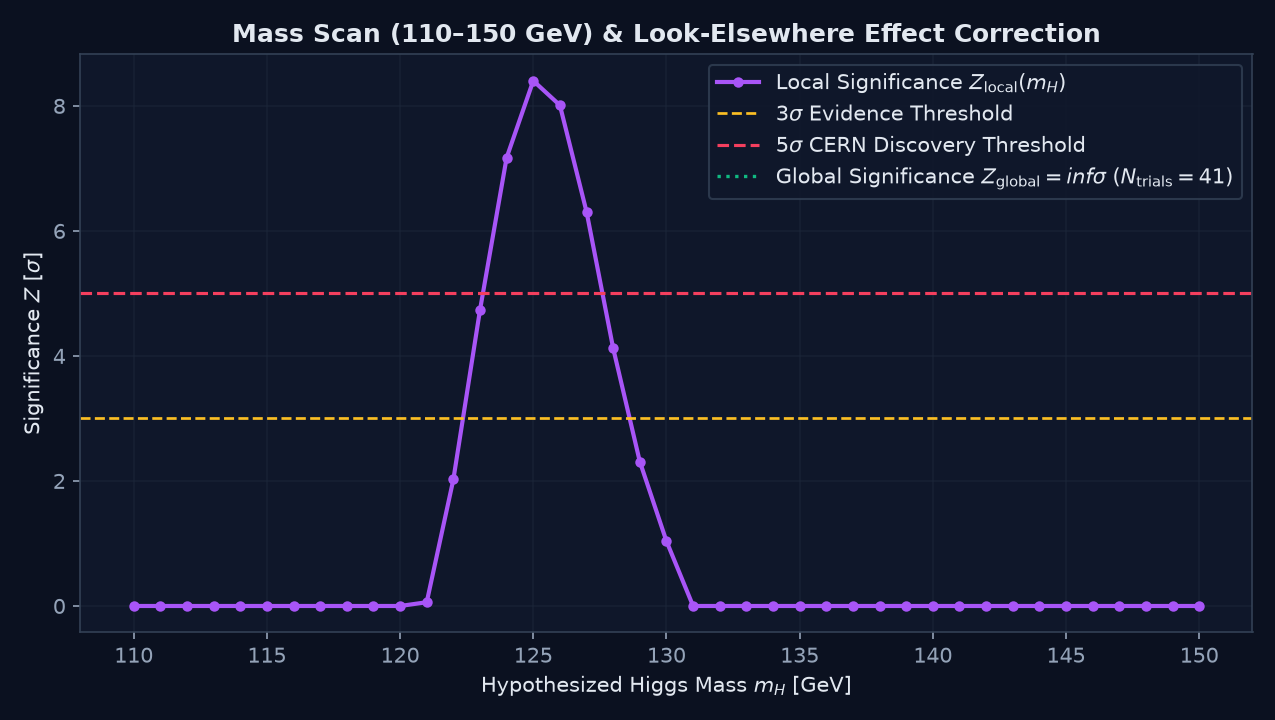

In [4]:
mass_grid = np.linspace(110.0, 150.0, 41)
scan_res = mass_scan(counts, edges, s_nom=s_nom, mass_grid=mass_grid, sigma=1.5)

print(f"Best mass hypothesis: {scan_res['best_m_h']:.1f} GeV")
print(f"Max Local Significance:  {scan_res['max_z_local']:.2f} sigma (p_local = {scan_res['p_local']:.2e})")
print(f"Global Significance:     {scan_res['z_global']:.2f} sigma (p_global = {scan_res['p_global']:.2e})")

plt.figure(figsize=(8.5, 4.8))
plt.plot(scan_res['masses'], scan_res['z_local'], '-o', markersize=4, label='Local Significance Z_local(m_H)')
plt.axhline(3.0, linestyle='--', label='3 sigma Evidence')
plt.axhline(5.0, linestyle='--', label='5 sigma Discovery')
plt.axhline(scan_res['z_global'], linestyle=':', label=f"Global Significance Z_global = {scan_res['z_global']:.2f} sigma")
plt.xlabel('Hypothesized Mass m_H [GeV]')
plt.ylabel('Significance Z [sigma]')
plt.legend()
plt.tight_layout()
plt.show()